In [34]:
# Data Analysis for Mice Protein Expression dataset (Down Syndrome study)
# Author: [Nitesh Bansal]
# PHYS3130 W2025
#Comments generated by gpt
#Used substack ex and other useful links to hell

In [26]:
# Import necessary libraries for data manipulation, analysis, and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, auc, RocCurveDisplay, classification_report
from scipy.stats import ttest_ind

In [27]:
# Load the Mice Protein Expression dataset (Down Syndrome experiment) from CSV.
# The dataset is small, so we can load it directly without using a database.
data = pd.read_csv('Data_Cortex_Nuclear.csv')
print("Data shape (rows, columns):", data.shape)
print(data.head())

Data shape (rows, columns): (1080, 82)
  MouseID  DYRK1A_N   ITSN1_N    BDNF_N     NR1_N    NR2A_N    pAKT_N  \
0   309_1  0.503644  0.747193  0.430175  2.816329  5.990152  0.218830   
1   309_2  0.514617  0.689064  0.411770  2.789514  5.685038  0.211636   
2   309_3  0.509183  0.730247  0.418309  2.687201  5.622059  0.209011   
3   309_4  0.442107  0.617076  0.358626  2.466947  4.979503  0.222886   
4   309_5  0.434940  0.617430  0.358802  2.365785  4.718679  0.213106   

    pBRAF_N  pCAMKII_N   pCREB_N  ...   pCFOS_N     SYP_N  H3AcK18_N  \
0  0.177565   2.373744  0.232224  ...  0.108336  0.427099   0.114783   
1  0.172817   2.292150  0.226972  ...  0.104315  0.441581   0.111974   
2  0.175722   2.283337  0.230247  ...  0.106219  0.435777   0.111883   
3  0.176463   2.152301  0.207004  ...  0.111262  0.391691   0.130405   
4  0.173627   2.134014  0.192158  ...  0.110694  0.434154   0.118481   

     EGR1_N  H3MeK4_N    CaNA_N  Genotype  Treatment  Behavior   class  
0  0.131790  0.1

In [28]:
# Data preprocessing and cleaning:
# Check for missing values in each protein feature
missing_counts = data.isna().sum()
print("\nNumber of missing values per column (if any):")
print(missing_counts[missing_counts > 0])

# Identify features to drop due to excessive missing data.
# We set a threshold at >10% missing values (around 108 out of ~1080 measurements)
# to drop a protein feature as unreliable.
features_to_drop = missing_counts[missing_counts > 108].index.tolist()
print("\nFeatures to drop due to many missing values:", features_to_drop)

# Drop those features from the dataset
data_clean = data.drop(columns=features_to_drop)

# Impute remaining missing values with the mean of each feature (for numeric columns)
data_clean = data_clean.fillna(data_clean.mean(numeric_only=True))


Number of missing values per column (if any):
DYRK1A_N        3
ITSN1_N         3
BDNF_N          3
NR1_N           3
NR2A_N          3
pAKT_N          3
pBRAF_N         3
pCAMKII_N       3
pCREB_N         3
pELK_N          3
pERK_N          3
pJNK_N          3
PKCA_N          3
pMEK_N          3
pNR1_N          3
pNR2A_N         3
pNR2B_N         3
pPKCAB_N        3
pRSK_N          3
AKT_N           3
BRAF_N          3
CAMKII_N        3
CREB_N          3
ELK_N          18
ERK_N           3
GSK3B_N         3
JNK_N           3
MEK_N           7
TRKA_N          3
RSK_N           3
APP_N           3
Bcatenin_N     18
SOD1_N          3
MTOR_N          3
P38_N           3
pMTOR_N         3
DSCR1_N         3
AMPKA_N         3
NR2B_N          3
pNUMB_N         3
RAPTOR_N        3
TIAM1_N         3
pP70S6_N        3
BAD_N         213
BCL2_N        285
pCFOS_N        75
H3AcK18_N     180
EGR1_N        210
H3MeK4_N      270
dtype: int64

Features to drop due to many missing values: ['BAD_N', 'B

In [29]:
# Aggregate data by MouseID to get one record per mouse (average technical replicates).
data_clean['MouseBase'] = data_clean['MouseID'].apply(lambda x: x.split('_')[0])
mouse_data = data_clean.groupby('MouseBase').agg({
    **{col: 'mean' for col in data_clean.columns if col not in ['MouseID','MouseBase','Genotype','Treatment','Behavior','class']},
    **{'Genotype': 'first', 'Treatment': 'first', 'Behavior': 'first', 'class': 'first'}
}).reset_index()

print("\nShape after aggregating replicates (should be 72 x [features]):", mouse_data.shape)

# Separate features and labels for clarity
feature_cols = [col for col in mouse_data.columns if col not in ['MouseBase','Genotype','Treatment','Behavior','class']]
X = mouse_data[feature_cols].copy()             # feature matrix (protein expression levels)
y_class = mouse_data['class'].copy()           # multi-class label (combination of genotype, treatment, behavior)
y_genotype = mouse_data['Genotype'].apply(lambda g: 1 if g == 'Ts65Dn' else 0)  # binary genotype label (1 = Ts65Dn, 0 = Control)

# Standardize features (zero mean, unit variance) for PCA and classification
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=feature_cols)


Shape after aggregating replicates (should be 72 x [features]): (72, 77)



Number of mice in each class:
class
c-CS-m    10
c-SC-m    10
t-SC-m     9
t-CS-m     9
c-SC-s     9
t-SC-s     9
c-CS-s     9
t-CS-s     7
Name: count, dtype: int64

Example: Mean +/- STD of a few proteins for each genotype:
APP_N: Control = 0.375±0.036, Ts65Dn = 0.439±0.041
SOD1_N: Control = 0.530±0.246, Ts65Dn = 0.557±0.298
CaNA_N: Control = 1.324±0.307, Ts65Dn = 1.353±0.302
NR2A_N: Control = 3.985±0.638, Ts65Dn = 3.687±0.619

Proteins with significant differences (unadjusted p<0.05): Genotype = 11, Behavior = 44, Treatment = 10
Top 5 genotype-difference proteins (p-values): [('APP_N', np.float64(1.5618888933216148e-09)), ('S6_N', np.float64(0.0012527082241416104)), ('GluR3_N', np.float64(0.009957968924019341)), ('Tau_N', np.float64(0.013766233973565557)), ('pPKCG_N', np.float64(0.018445848722204516))]
Top 5 training-difference proteins (p-values): [('CaNA_N', np.float64(3.6005151714850653e-16)), ('SOD1_N', np.float64(4.246402318761434e-14)), ('P38_N', np.float64(6.883650861256225e

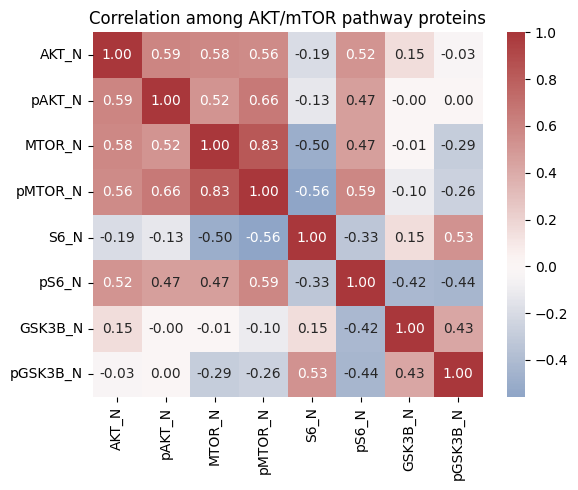

<ipython-input-30-a63c38f01609>:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=mouse_data['Behavior'], y=mouse_data['CaNA_N'], palette="Set2")


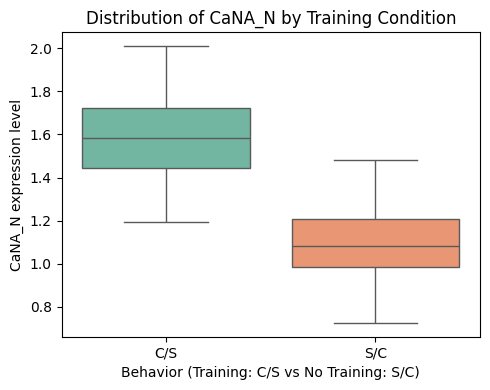

In [30]:
# Count how many mice are in each class.
# (Each class represents a unique combination of genotype, drug treatment, and training status)
class_counts = mouse_data['class'].value_counts()
print("\nNumber of mice in each class:")
print(class_counts)

# Compare protein expression by genotype: compute mean and std for each feature in Control vs Ts65Dn groups
means_genotype = mouse_data.groupby('Genotype')[feature_cols].mean()
stds_genotype = mouse_data.groupby('Genotype')[feature_cols].std()
print("\nExample: Mean +/- STD of a few proteins for each genotype:")
# Show mean ± std for select proteins (APP_N, SOD1_N, CaNA_N, NR2A_N)
# APP_N and SOD1_N are chromosome 21 proteins often elevated in DS;
# CaNA_N and NR2A_N are synaptic plasticity-related proteins.
for prot in ['APP_N', 'SOD1_N', 'CaNA_N', 'NR2A_N']:
    if prot in means_genotype.columns:
        ctrl_mean = means_genotype.loc['Control', prot]
        ctrl_std = stds_genotype.loc['Control', prot]
        ts_mean = means_genotype.loc['Ts65Dn', prot]
        ts_std = stds_genotype.loc['Ts65Dn', prot]
        print(f"{prot}: Control = {ctrl_mean:.3f}±{ctrl_std:.3f}, Ts65Dn = {ts_mean:.3f}±{ts_std:.3f}")

# Prepare boolean masks to subset data by group for statistical comparisons
control_idx = mouse_data['Genotype'] == 'Control'
ts_idx = mouse_data['Genotype'] == 'Ts65Dn'
CS_idx = mouse_data['Behavior'] == 'C/S'      # C/S = trained (context-shock)
SC_idx = mouse_data['Behavior'] == 'S/C'      # S/C = untrained (shock-context control)
mem_idx = mouse_data['Treatment'] == 'Memantine'
sal_idx = mouse_data['Treatment'] == 'Saline'

# Perform two-sample t-tests (Welch's t-test) for each protein feature across different conditions:
# - Genotype: Control vs Ts65Dn
# - Training (Behavior): C/S vs S/C
# - Treatment: Memantine vs Saline
# This reveals which proteins have significant expression differences for each factor.
pvals_genotype = {}
pvals_behavior = {}
pvals_treatment = {}
for col in feature_cols:
    # Genotype effect
    stat, p = ttest_ind(X.loc[control_idx, col], X.loc[ts_idx, col], equal_var=False)
    pvals_genotype[col] = p
    # Training/Behavior effect
    stat, p = ttest_ind(X.loc[CS_idx, col], X.loc[SC_idx, col], equal_var=False)
    pvals_behavior[col] = p
    # Treatment effect
    stat, p = ttest_ind(X.loc[mem_idx, col], X.loc[sal_idx, col], equal_var=False)
    pvals_treatment[col] = p

# Count how many proteins show nominal significance (p < 0.05, unadjusted) for each factor
sig_genotype = sum(1 for p in pvals_genotype.values() if p < 0.05)
sig_behavior = sum(1 for p in pvals_behavior.values() if p < 0.05)
sig_treatment = sum(1 for p in pvals_treatment.values() if p < 0.05)
print(f"\nProteins with significant differences (unadjusted p<0.05): Genotype = {sig_genotype}, Behavior = {sig_behavior}, Treatment = {sig_treatment}")

# Identify the top 5 most significantly changed proteins for each factor (smallest p-values)
top5_genotype = sorted(pvals_genotype.items(), key=lambda x: x[1])[:5]
top5_behavior = sorted(pvals_behavior.items(), key=lambda x: x[1])[:5]
top5_treatment = sorted(pvals_treatment.items(), key=lambda x: x[1])[:5]
print("Top 5 genotype-difference proteins (p-values):", top5_genotype)
print("Top 5 training-difference proteins (p-values):", top5_behavior)
print("Top 5 treatment-difference proteins (p-values):", top5_treatment)

# Visualize correlation within a key signaling pathway (AKT/mTOR).
# We select proteins from the AKT/mTOR pathway (AKT, MTOR, S6, GSK3B and their phosphorylated forms)
# and compute their correlations.
# This pathway is critical for synaptic plasticity and memory formation,
# and is targeted by treatments (e.g., memantine) in DS.
subset_feats = ['AKT_N','pAKT_N','MTOR_N','pMTOR_N','S6_N','pS6_N','GSK3B_N','pGSK3B_N']
corr_matrix = X[subset_feats].corr()
plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix, annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Correlation among AKT/mTOR pathway proteins")
plt.tight_layout()
plt.savefig("corr_heatmap.png", dpi=300)
plt.show()

# Example visualization: distribution of a protein by training group.
# Plot CaNA_N (Calcineurin A) expression for trained vs untrained mice to illustrate a strong training effect.
plt.figure(figsize=(5,4))
sns.boxplot(x=mouse_data['Behavior'], y=mouse_data['CaNA_N'], palette="Set2")
plt.title("Distribution of CaNA_N by Training Condition")
plt.xlabel("Behavior (Training: C/S vs No Training: S/C)")
plt.ylabel("CaNA_N expression level")
plt.tight_layout()
plt.savefig("CaNA_boxplot.png", dpi=300)
plt.show()



Explained variance by PC1, PC2, PC3: [0.27168466 0.19309256 0.10078579]


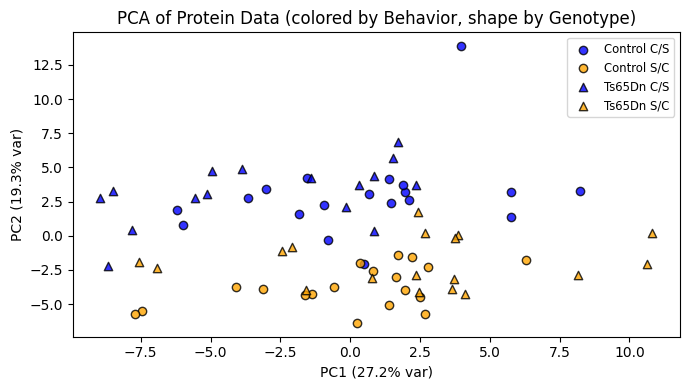

In [31]:
# Dimensionality reduction with PCA to identify primary axes of variation in the proteomic data
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)
print("\nExplained variance by PC1, PC2, PC3:", pca.explained_variance_ratio_[:3])

# Visualize the data in the space of the first two principal components (PC1 vs PC2)
pc1 = X_pca[:, 0]
pc2 = X_pca[:, 1]
# Plot each mouse in PC1-PC2 space, colored by training status (C/S vs S/C) and different marker for genotype
plt.figure(figsize=(7,4))
for gen, mark in [('Control','o'), ('Ts65Dn','^')]:
    for beh, col in [('C/S','blue'), ('S/C','orange')]:
        mask = (mouse_data['Genotype'] == gen) & (mouse_data['Behavior'] == beh)
        plt.scatter(pc1[mask], pc2[mask], c=col, marker=mark, edgecolors='k', label=f"{gen} {beh}", alpha=0.8)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
plt.title("PCA of Protein Data (colored by Behavior, shape by Genotype)")
plt.legend(loc='best', fontsize='small')
plt.tight_layout()
plt.savefig("PCA_scatter.png", dpi=300)
plt.show()



Genotype Classification Accuracy: 88.89%
Confusion Matrix (Actual [rows] vs Predicted [cols], 0=Control, 1=Ts65Dn):
 [[8 2]
 [0 8]]
AUC (ROC): 0.9625000000000001


<Figure size 640x480 with 0 Axes>

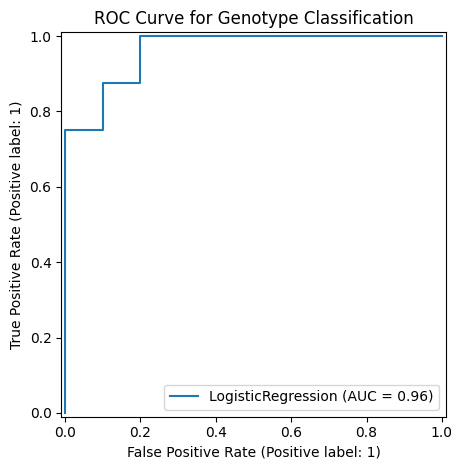

Top 5 features favoring Ts65Dn classification: ['APP_N', 'TIAM1_N', 'TRKA_N', 'DSCR1_N', 'pNR2B_N']
Top 5 features favoring Control classification: ['SYP_N', 'AMPKA_N', 'NR1_N', 'GluR3_N', 'ERK_N']


In [32]:
# Goal: use protein profiles to predict genotype
# (whether a mouse is Ts65Dn Down syndrome model or a control)
# Split data into training and test sets (25% test) with stratification by genotype to preserve class proportions
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_genotype, test_size=0.25, stratify=y_genotype, random_state=42)
# Initialize a logistic regression classifier for binary genotype prediction
clf_log = LogisticRegression(max_iter=1000, random_state=0)
# Train the model on the training data
clf_log.fit(X_train, y_train)
# Predict the genotype for the test set and obtain predicted probabilities for ROC curve
y_pred = clf_log.predict(X_test)
y_proba = clf_log.predict_proba(X_test)[:, 1]

# Evaluate classifier performance on the test set
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
print(f"\nGenotype Classification Accuracy: {acc*100:.2f}%")
print("Confusion Matrix (Actual [rows] vs Predicted [cols], 0=Control, 1=Ts65Dn):\n", cm)
print("AUC (ROC):", roc_auc)

# Plot the ROC curve for the genotype classifier
plt.figure()
RocCurveDisplay.from_estimator(clf_log, X_test, y_test)
plt.title("ROC Curve for Genotype Classification")
plt.tight_layout()
plt.savefig("ROC_curve.png", dpi=300)
plt.show()

# Examine logistic regression coefficients to identify important proteins for genotype prediction
coef = pd.Series(clf_log.coef_[0], index=feature_cols)
# The largest positive coefficients correspond to proteins more abundant in Ts65Dn,
# whereas the most negative coefficients correspond to proteins more abundant in controls.
print("Top 5 features favoring Ts65Dn classification:", coef.nlargest(5).index.tolist())
print("Top 5 features favoring Control classification:", coef.nsmallest(5).index.tolist())


In [33]:
# Goal: predict each mouse's specific experimental class
# (the combination of genotype, treatment, and training condition)
# Use Random Forest classifier and cross-validation to evaluate multi-class classification
clf_rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=0)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
cv_scores = cross_val_score(clf_rf, X_scaled, y_class, cv=cv, scoring='accuracy')
print(f"\n8-class classification accuracy (5-fold CV): {np.mean(cv_scores)*100:.1f}% (std = {np.std(cv_scores)*100:.1f}%)")

# Train Random Forest on the full data to compute feature importances for the 8-class problem
clf_rf.fit(X_scaled, y_class)
importances = pd.Series(clf_rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("Top 10 feature importances for 8-class classification:")
print(importances.head(10))

# (Optional) Generate confusion matrix and classification report for one train-test split (for demonstration of class-wise performance)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_scaled, y_class, test_size=0.25, stratify=y_class, random_state=42)
clf_rf2 = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=0)
clf_rf2.fit(X_train_c, y_train_c)
y_pred_c = clf_rf2.predict(X_test_c)
cm_multi = confusion_matrix(y_test_c, y_pred_c, labels=clf_rf2.classes_)
print("\nConfusion matrix for an example 8-class test split:")
print("Classes:", clf_rf2.classes_)
print(cm_multi)
print("\nClassification report:")
print(classification_report(y_test_c, y_pred_c))



8-class classification accuracy (5-fold CV): 54.1% (std = 8.5%)
Top 10 feature importances for 8-class classification:
SOD1_N     0.052106
pERK_N     0.039497
ITSN1_N    0.038228
BRAF_N     0.032096
pS6_N      0.029781
pPKCG_N    0.028890
CaNA_N     0.028846
SNCA_N     0.027520
pNUMB_N    0.026817
AKT_N      0.026762
dtype: float64

Confusion matrix for an example 8-class test split:
Classes: ['c-CS-m' 'c-CS-s' 'c-SC-m' 'c-SC-s' 't-CS-m' 't-CS-s' 't-SC-m' 't-SC-s']
[[0 0 0 0 1 0 1 1]
 [1 1 0 0 0 0 0 0]
 [0 0 1 0 0 0 2 0]
 [0 0 0 1 0 0 1 0]
 [0 0 0 0 2 0 0 0]
 [1 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 2 0]
 [0 0 0 0 0 0 0 2]]

Classification report:
              precision    recall  f1-score   support

      c-CS-m       0.00      0.00      0.00         3
      c-CS-s       1.00      0.50      0.67         2
      c-SC-m       1.00      0.33      0.50         3
      c-SC-s       1.00      0.50      0.67         2
      t-CS-m       0.67      1.00      0.80         2
      t-CS-s       1.00    